# Modelo de linguagem pequeno do zero, modo autorregressivo

Este notebook constrói do zero um modelo de linguagem pequeno que gera texto da esquerda para a direita, um token por vez, como os grandes modelos de linguagem atuais. O notebook irmão, `slm_difusao.ipynb`, treina a mesma arquitetura, com pesos próprios, no modo de difusão mascarada, e os dois repetem de propósito as caixas que têm em comum, para que cada um possa ser lido sozinho.

Cada seção corresponde a uma caixa do diagrama de arquitetura do projeto e é contada em três partes. A teoria vem decomposta em blocos de construção matemáticos, a aplicação roda o código e mostra o que entra e o que sai, e a técnica traz os problemas que o projeto encontrou e como foram resolvidos. Nada aqui usa pesos ou tokenizador pré-treinados.

Projeto, decisões e referências em [https://github.com/pcbrom/homebrewed-slms](https://github.com/pcbrom/homebrewed-slms). Para rodar no Colab, escolha **Ambiente de execução, Alterar o tipo de ambiente de execução, GPU T4** e execute as células em ordem.

Se este material for útil para você, deixe uma estrela no repositório e cite-o pelo `CITATION.cff`.

O pacote `slm/` foi escrito com identificadores em português, como `treinar`, `janelar`, `mascarar` e `perda`, então o código se lê na mesma língua do texto. Por convenção de programação, os identificadores não levam acento, e por isso o modo aparece no código como `autoregressivo` ou `difusao`.

In [1]:
import os, subprocess, sys
LOCAL = os.environ.get("SLM_LOCAL")
if LOCAL:
    RAIZ = LOCAL
else:
    RAIZ = "/content/homebrewed-slms"
    if not os.path.exists(RAIZ):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pcbrom/homebrewed-slms", RAIZ], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "tokenizers==0.23.3", "regex"], check=True)
sys.path.insert(0, RAIZ)
os.chdir(RAIZ)
import torch
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
print("dispositivo:", DISPOSITIVO, torch.cuda.get_device_name(0) if DISPOSITIVO == "cuda" else "")

dispositivo: cuda NVIDIA GeForce RTX 5090


## O fluxo completo

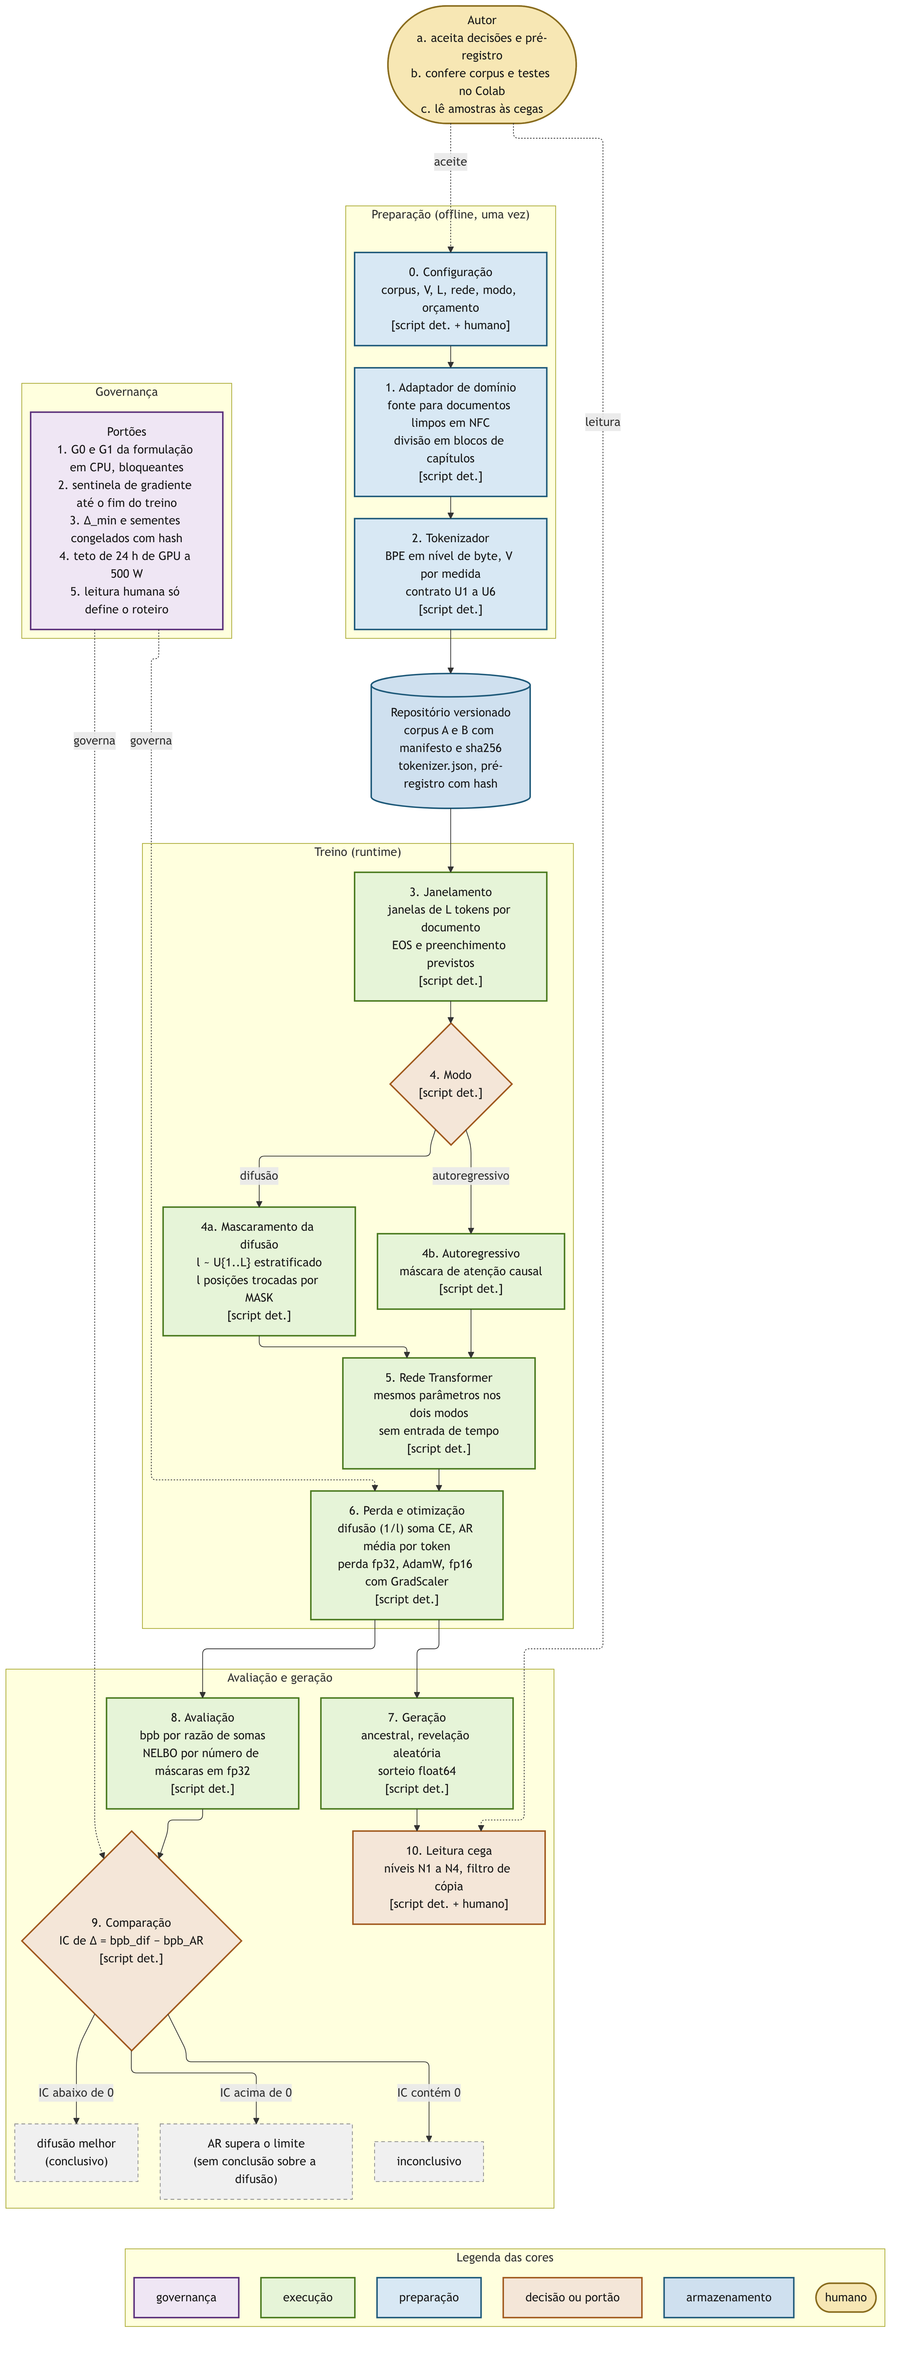

A preparação (caixas 0 a 2) roda uma única vez e deixa no repositório o corpus limpo e o tokenizador. O treino (caixas 3 a 6) é igual nos dois modos até a caixa 4, onde a difusão troca tokens por `[MASK]` e o modo autorregressivo usa atenção causal. A avaliação e a geração (caixas 7 a 10) medem o que o modelo aprendeu. Este notebook segue o ramo autorregressivo da caixa 4, com máscara de atenção causal.

## Mapa matemático, do texto à medida

Cada caixa recebe um objeto matemático e entrega outro. A tabela fixa a notação usada no notebook inteiro, e a cadeia logo abaixo mostra como os blocos se encaixam.

| Símbolo | Significado | Onde nasce |
|---|---|---|
| $d$, $B_d$ | um documento (capítulo ou lei) e o número de bytes dele em UTF-8, depois da NFC | caixa 1, `slm/dados.py` |
| $\tau(d) = (t_1, \dots, t_n)$ | ids dos tokens do documento, com $t_i \in \{4, \dots, V-1\}$ | caixa 2, `slm/tokenizador.py` |
| $w \in \{0, \dots, V-1\}^L$ | uma janela de $L$ tokens | caixa 3, `slm/janelas.py` |
| $x$ | janela deslocada por um BOS, lida com máscara causal | caixa 4, `slm/perda.py` |
| $f_\theta$, $p_\theta$ | rede com parâmetros $\theta$ e as distribuições condicionais que ela define | caixa 5, `slm/modelo.py` |
| $\ell_{AR}(w)$ | log-verossimilhança negativa de uma janela, em nats | caixa 6, `slm/perda.py` |
| $\mathrm{NLL}(d)$, $\mathrm{bpb}$ | perda de um documento e bits por byte | caixa 8, `slm/avaliacao.py` |
| IC | intervalo de confiança dos bits por byte | caixa 9, `slm/estatistica.py` |

Alguns símbolos carregam dois sentidos, e o contexto os separa. $d$ é documento e largura da rede, $S$ é o conjunto mascarado e a escala do GradScaler, $T$ é o número de passos da geração e a temperatura, $K$ é a matriz de chaves e o número de estimativas por janela, e $t$ é o tempo da difusão enquanto $t_i$ é um token. Os logits da rede são escritos $o$, para não se confundirem com a janela mascarada $z$.

$$
\underbrace{d}_{\text{caixa 1}}
\xrightarrow{\ \tau\ }
\underbrace{(t_1,\dots,t_n)}_{\text{caixa 2}}
\xrightarrow{\ \oplus\,\mathrm{EOS},\ \text{corte em } L\ }
\underbrace{w}_{\text{caixa 3}}
\xrightarrow{\ \text{deslocar}\ }
\underbrace{x}_{\text{caixa 4}}
\xrightarrow{\ f_\theta\ }
\underbrace{p_\theta(w_i \mid w_{<i})}_{\text{caixa 5}}
\xrightarrow{\ -\log\ }
\underbrace{\ell_{AR}(w)}_{\text{caixa 6}}
\xrightarrow{\ \sum_{w \in d}\ }
\underbrace{\mathrm{NLL}(d)}_{\text{caixa 8}}
\xrightarrow{\ \sum_d / (\ln 2 \sum_d B_d)\ }
\underbrace{\mathrm{bpb} \pm \mathrm{IC}}_{\text{caixas 8 e 9}}
$$

O treino (caixa 6) fecha um laço sobre essa cadeia, porque o gradiente da perda em relação a $\theta$ volta à caixa 5 e altera $f_\theta$. A geração (caixa 7) percorre o mesmo $p_\theta$ no sentido contrário, um token por vez, da esquerda para a direita.

## Caixa 0. Configuração

> **O que muda em relação ao notebook da difusão.** A configuração é a mesma, exceto por `MODO`, que aqui vale `"autoregressivo"` e no notebook da difusão vale `"difusao"`. A técnica traz a vazão medida deste modo.

### Teoria

Uma corrida é descrita por um único objeto. Trocar o domínio, o tamanho da rede ou o modo significa mudar campos aqui, e nada mais. `CORPUS` escolhe o texto de treino, `"A"` para a prosa de Machado de Assis e `"B"` para leis federais brasileiras, e `EPOCAS_AULA` define quantas vezes o treino ao vivo percorre o texto.

Antes de treinar, vale estimar quanto texto a sua GPU processa por hora e quanto texto o modelo precisa ver. A dedução completa está em `docs/DIMENSIONAMENTO.md`, e a célula abaixo roda o mesmo cálculo para uma T4.

### Blocos de construção

**Bloco 0.1, parâmetros sem o embedding.** Cada bloco do Transformer tem as projeções de atenção $Q$, $K$ e $V$ e a projeção de saída, que somam $4d^2$ pesos, além de um MLP de largura $4d$, com $8d^2$ pesos. Daí $N = 12\, n_{layer}\, d^2$, desprezando vieses e normalizações. Código em `scripts/dimensionar.py`.

**Bloco 0.2, custo de um token de treino.** A passagem direta custa $2N$ nos produtos de matrizes das camadas, $2\, n_{layer}\, L\, d$ no produto $QK^\top$ da atenção e $2\, d\, V$ na projeção de saída. Essa é a convenção de Kaplan et al. (2020). O PaLM (Chowdhery et al., 2022) conta também o produto da atenção pelos valores, o que dobra o termo da atenção. A retropropagação custa cerca do dobro da passagem direta, e assim, na convenção de Kaplan,

$$C_{treino} = 6N + 6\, n_{layer}\, L\, d + 6\, d\, V.$$

**Bloco 0.3, vazão e tempo.** Com pico $P$ e utilização MFU, a vazão é $P \cdot \mathrm{MFU} / C_{treino}$ tokens por segundo, e o tempo para ver $D$ tokens é $D$ dividido por ela. É esse número que decide quantas épocas e quantas sementes cabem no orçamento das caixas 6 e 9.

In [2]:
n_layer, d, L_, V_ = 6, 384, 256, 4096
N = 12 * n_layer * d * d
C = 6 * N + 6 * n_layer * L_ * d + 6 * d * V_
print(f"N = {N:,} | C_treino = {C / 1e6:.1f} MFLOP por token | {C / (6 * N) - 1:.1%} acima de 6N")

N = 10,616,832 | C_treino = 76.7 MFLOP por token | 20.4% acima de 6N


### Aplicação

In [3]:
from slm.config import Config
MODO = "autoregressivo"
CORPUS = os.environ.get("SLM_CORPUS", "A")
EPOCAS_AULA = float(os.environ.get("SLM_EPOCAS", "16"))
cfg_base = dict(L=256, n_layer=6, d=384, n_head=6, lote=64, epocas=EPOCAS_AULA, lr=1e-3,
                precisao="fp16" if DISPOSITIVO == "cuda" else "fp32",
                atencao="efficient" if DISPOSITIVO == "cuda" else "math", papel="aula", corpus=CORPUS)
print("modo:", MODO, "|", cfg_base)
print(subprocess.run([sys.executable, "scripts/dimensionar.py", "--pico-tflops", "65", "--vram-gb", "16",
                      "--arq", "6x384", "--vocab", "4096", "--horas", "0.25"],
                     check=True, capture_output=True, text=True).stdout)

modo: autoregressivo | {'L': 256, 'n_layer': 6, 'd': 384, 'n_head': 6, 'lote': 64, 'epocas': 16.0, 'lr': 0.001, 'precisao': 'fp16', 'atencao': 'efficient', 'papel': 'aula', 'corpus': 'A'}
pico 65.0 TFLOPS | VRAM 16.0 GB | ctx 256 | vocab 4096 | 20 tokens/param (com embedding)

    arq       N   N+emb  FLOP/tok  extra mem AdamW tokens alvo    tok/s@0.3  tempo@0.3    tok/s@0.5  tempo@0.5
  6x384   10.6M   12.2M     76.7M    20%     1.1%V      243.8M       254.3k     16 min       423.9k     10 min

extra: custo de atencao e da camada de saida acima de 6N | mem AdamW: fracao da VRAM antes das ativacoes

orcamento de 0.25 h, aproximacao C = 6 N D com D = 20 N:
  MFU 0.3: C = 1.76e+16 FLOP, N otimo ~ 12.1M, D ~ 241.9M tokens
  MFU 0.5: C = 2.92e+16 FLOP, N otimo ~ 15.6M, D ~ 312.2M tokens



### Técnica

**A fórmula curta engana em modelo pequeno.** A estimativa usual de custo, $6N$ operações por token, ignora a atenção e a camada de saída sobre o vocabulário. Num modelo de 4 camadas com $d = 256$ e vocabulário de 8 mil tokens, os dois termos acrescentam 73% ao custo, 65 pontos da camada de saída e 8 da atenção. O `scripts/dimensionar.py` usa a fórmula completa.

**Estimar, depois medir.** A fração do pico que o treino realmente aproveita (MFU) não sai da ficha técnica. Numa RTX 5090 limitada a 500 W, o modo autorregressivo processou 1,13 milhão de tokens por segundo em fp16. Isso dá MFU de 0,41 quando a atenção conta só o produto $QK^\top$, convenção de Kaplan et al. (2020), e de 0,43 quando conta também o produto pelos valores, convenção do PaLM (Chowdhery et al., 2022). O pico de 209,5 TFLOPS do denominador vem de fontes secundárias e não foi conferido no documento técnico da NVIDIA. Com a vazão medida, o plano de pesquisa caberia em cerca de 5,6 horas de treino, sem contar a avaliação, quando a estimativa sem medida ia de 7,5 a 45 horas.

## Caixa 1. Adaptador de domínio

> **O que muda em relação ao notebook da difusão.** Nada. Esta caixa é idêntica nos dois notebooks.

### Teoria

Entra o texto de uma fonte e saem documentos limpos em NFC, cada um com grupo, partição e contagem de bytes.

O corpus A reúne as obras em prosa de Machado de Assis do Projeto Gutenberg, em domínio público e na grafia original das edições de época ("elle", "annos"). Cada capítulo é um documento. A divisão reserva para validação e teste blocos contíguos de capítulos inteiros de cada obra, com um capítulo de margem antes de cada bloco retido, e o tokenizador só é treinado depois da divisão, para que nenhuma estatística do texto de avaliação vaze para o vocabulário.

### Blocos de construção

**Bloco 1.1, normalização.** Todo texto passa por $u \mapsto \mathrm{NFC}(u)$, a forma canônica composta do Unicode. Depois dela, cada caractere acentuado do português é um único ponto de código.

**Bloco 1.2, bytes.** $B_d = |\mathrm{UTF8}(\mathrm{NFC}(d))|$. É o denominador dos bits por byte da caixa 8, e por isso é contado aqui, uma única vez, e nunca sobre o texto que o tokenizador reconstrói.

**Bloco 1.3, partição.** Cada obra é uma sequência de capítulos $c_1, \dots, c_m$. A divisão manda um primeiro bloco para o treino, um capítulo para a margem, um bloco contíguo para a validação, outro capítulo para a margem e o bloco final para o teste, cada bloco retido com pelo menos 5 capítulos e 30 KB. *Papéis avulsos*, com 12 contos, comporta só o bloco de validação e fica fora do teste. A partição é função do documento e fica fixada antes de qualquer treino. Código em `slm/dados.py`.

In [4]:
import unicodedata
from slm.corpus import ler_documentos
docs = ler_documentos(CORPUS)
d0 = docs[0]
print(d0["doc_id"], "| já em NFC:", unicodedata.is_normalized("NFC", d0["texto"]),
      "| B_d recontado:", len(d0["texto"].encode("utf-8")), "= bytes guardados:", d0["bytes"])

A-55752-c001 | já em NFC: True | B_d recontado: 1956 = bytes guardados: 1956


### Aplicação

In [5]:
import collections
from slm.corpus import ler_documentos
docs = ler_documentos(CORPUS)
por_particao = collections.Counter(d["particao"] for d in docs)
bytes_particao = collections.Counter()
for d in docs:
    bytes_particao[d["particao"]] += d["bytes"]
for p in ("treino", "margem", "validacao", "teste"):
    print(f"{p:10s} {por_particao[p]:5d} documentos {bytes_particao[p] / 1e6:7.3f} MB")
exemplo = next(d for d in docs if d["particao"] == "treino")
print("\nexemplo:", exemplo["doc_id"], exemplo["grupo"], exemplo["bytes"], "bytes")
print(exemplo["texto"][:600])

treino       650 documentos   2.221 MB
margem        19 documentos   0.177 MB
validacao    109 documentos   0.540 MB
teste        110 documentos   0.475 MB

exemplo: A-55752-c001 dom_casmurro 1956 bytes
Do titulo.

Uma noite destas, vindo da cidade para o Engenho Novo, encontrei no trem da Central um rapaz aqui do bairro, que eu conheço de vista e de chapéo. Comprimentou-me, sentou-se ao pé de mim, falou da lua e dos ministros, e acabou recitando-me versos. A viagem era curta, e os versos póde ser que não fossem inteiramente maus. Succedeu, porém, que como eu estava cançado, fechei os olhos tres ou quatro vezes; tanto bastou para que elle interrompesse a leitura e mettesse os versos no bolso.

--Continue, disse eu accordando.

--Já acabei, murmurou elle.

--São muito bonitos.

Vi-lhe fazer um


### Técnica

**Uma obra "em prosa" que não era só prosa.** *Relíquias de casa velha* traz um soneto e duas comédias. Misturar verso e teatro num corpus de prosa muda a distribuição que o modelo aprende, e a obra saiu, junto com as *Poesias completas*. A lição é inspecionar o conteúdo, sem confiar no rótulo da obra.

**Uma divisão que vaza.** Sortear documentos ao acaso colocaria capítulos vizinhos da mesma obra no treino e na validação. A solução foram blocos contíguos de capítulos inteiros, com um capítulo de margem entre o treino e a validação e outro entre a validação e o teste. Os nomes próprios ainda vazam. Numa amostra de 4 obras, examinada antes da construção do corpus, de 46% a 97% dos nomes de um bloco retido já apareciam na parte de treino da mesma obra. Por isso o projeto mede os bits por byte com e sem os trechos de nomes.

**O preço de um bloco mínimo.** Exigir ao menos 5 capítulos e 30 KB na validação e no teste reduziu o texto de treino a 2,22 MB, contra cerca de 3,2 MB estimados. Em *Yayá Garcia*, o bloco de teste ficou maior que o de treino. Toda escolha de divisão custa dado de treino.

**Texto de formulário.** No corpus B, 23,1% das 728 leis de 2019 a 2022 da lista do Senado abrem créditos orçamentários com redação padronizada. Leis de crédito, orçamento e homenagem repetem a mesma fórmula de uma lei para outra, e a decisão do corpus retirou essas classes para que a medida reflita texto legislativo substantivo.

## Caixa 2. Tokenizador

> **O que muda em relação ao notebook da difusão.** Nada. Esta caixa é idêntica nos dois notebooks.

### Teoria

Entra texto e sai uma sequência de ids inteiros, com o caminho de volta.

O BPE em nível de byte parte dos 256 bytes como vocabulário e, a cada iteração, funde o par adjacente mais frequente num símbolo novo. Como qualquer texto é uma sequência de bytes, não existe token desconhecido, e $\mathrm{decode}(\mathrm{encode}(s)) = s$ para toda cadeia. Os ids de 0 a 3 ficam reservados para `[PAD]`, `[BOS]`, `[EOS]` e `[MASK]` e nunca são produzidos a partir de texto.

Abaixo, a implementação didática treina numa amostra pequena e mostra as primeiras fusões, como texto quando os bytes formam caracteres inteiros e como bytes crus quando não formam. Em seguida, o tokenizador do experimento, treinado pela biblioteca sobre o corpus inteiro, codifica uma frase. As duas implementações produzem as mesmas fusões e os mesmos ids, o que os testes do projeto verificam. O notebook do tokenizador, `slm_tokenizador.ipynb`, aprofunda esta caixa.

### Blocos de construção

**Bloco 2.1, alfabeto.** O vocabulário começa com os 256 bytes. Como todo texto é uma sequência de bytes, todo texto pode ser representado, e não existe token desconhecido.

**Bloco 2.2, contagem de pares.** Depois da pré-tokenização, o corpus vira um multiconjunto de palavras $w$ com frequência $f(w)$. Para cada par adjacente $(a, b)$, $c(a,b) = \sum_w f(w)\, \#\{(a,b) \text{ adjacentes em } w\}$.

**Bloco 2.3, fusão.** Escolhe-se $(a^*, b^*) = \arg\max c(a,b)$, com o empate decidido pelo menor par de ids, cria-se o símbolo $a^* b^*$ com o próximo id e reescrevem-se todas as palavras. Repete-se até haver $V$ símbolos.

**Bloco 2.4, codificação e decodificação.** A codificação aplica as fusões na ordem em que foram aprendidas, e a decodificação concatena os bytes de cada símbolo. Como toda fusão concatena bytes, $\mathrm{decode}(\mathrm{encode}(s)) = s$ para qualquer $s$. Código em `BPEDidatico.treinar`, `encode` e `decode`, no `slm/tokenizador.py`. A saída desta caixa, $\tau(d)$, é a entrada da caixa 3.

In [6]:
import collections, regex
from slm.tokenizador import GPT2_REGEX, ORDEM_BYTES, BPEDidatico
id_byte = {bytes([b]): i for i, b in enumerate(ORDEM_BYTES)}
amostra2 = [d["texto"] for d in docs if d["particao"] == "treino"][:5]
palavras = collections.Counter(tuple(bytes([b]) for b in p.encode()) for t in amostra2 for p in regex.findall(GPT2_REGEX, t))
cont = collections.Counter()
for p, f in palavras.items():
    for par in zip(p, p[1:]):
        cont[par] += f
a_mao = max(cont, key=lambda par: (cont[par], -id_byte[par[0]], -id_byte[par[1]]))
pelo_pacote = BPEDidatico().treinar(amostra2, 265).merges[0]
print("primeira fusão à mão:", a_mao, "| pelo pacote:", pelo_pacote, "| iguais:", a_mao == pelo_pacote, "| contagem:", cont[a_mao])

primeira fusão à mão: (b' ', b'd') | pelo pacote: (b' ', b'd') | iguais: True | contagem: 261


### Aplicação

In [7]:
from slm.tokenizador import BPEDidatico, BPEBiblioteca
amostra = [d["texto"] for d in docs if d["particao"] == "treino"][:20]
didatico = BPEDidatico().treinar(amostra, 256 + 4 + 40)
def mostrar(x):
    try:
        return repr(x.decode("utf-8"))
    except UnicodeDecodeError:
        return repr(x)
for a, b in didatico.merges[:15]:
    print(f"{mostrar(a):>12} + {mostrar(b):<12} -> {mostrar(a + b)}")
tok = BPEBiblioteca.carregar(f"tokenizador/{CORPUS}")
frase = "Capitú tinha olhos de ressaca, disse-lhe elle n'aquella hora."
ids = tok.encode(frase)
print("\nV =", tok.vocab_size, "| ids:", ids)
print("pedaços:", [tok.decode([i]).decode("utf-8", "replace") for i in ids])
print("ida e volta exata:", tok.decode(ids) == frase.encode("utf-8"))

         ' ' + 'a'          -> ' a'
         ' ' + 'd'          -> ' d'
         ' ' + 'e'          -> ' e'
         'r' + 'a'          -> 'ra'
         'o' + 's'          -> 'os'
         ' ' + 'p'          -> ' p'
         ' ' + 'm'          -> ' m'
         ' ' + 'c'          -> ' c'
         'q' + 'u'          -> 'qu'
         'a' + 's'          -> 'as'
        'qu' + 'e'          -> 'que'
        ' d' + 'e'          -> ' de'
     b'\xc3' + b'\xa3'      -> 'ã'
         'n' + 't'          -> 'nt'
         ' ' + 's'          -> ' s'

V = 4096 | ids: [3624, 545, 532, 269, 473, 400, 369, 15, 475, 16, 331, 415, 277, 10, 68, 794, 1382, 17]
pedaços: ['Capitú', ' tinha', ' olhos', ' de', ' res', 'sa', 'ca', ',', ' disse', '-', 'lhe', ' elle', ' n', "'", 'a', 'quella', ' hora', '.']
ida e volta exata: True


### Técnica

**Mesma letra, bytes diferentes.** Na NFC, "ã" é um único ponto de código. Na NFD, é um "a" seguido de um til combinante. A expressão regular da pré-tokenização separa a marca combinante da letra, e a palavra se desfaz. A célula abaixo mostra o efeito. A solução é normalizar o corpus em NFC uma única vez, antes de tudo, e contar os bytes da métrica sobre esse texto.

In [8]:
import unicodedata, regex
from slm.tokenizador import GPT2_REGEX
frase = "a ação do coração"
for forma in ("NFC", "NFD"):
    t = unicodedata.normalize(forma, frase)
    print(forma, len(t.encode()), "bytes |", regex.findall(GPT2_REGEX, t))

NFC 21 bytes | ['a', ' ação', ' do', ' coração']
NFD 25 bytes | ['a', ' ac', '̧', 'a', '̃', 'o', ' do', ' corac', '̧', 'a', '̃', 'o']


**Duas implementações, uma resposta.** Na amostra de 440 KB do corpus A, em 3.463 das 3.836 fusões (90%) mais de um par empatou na contagem máxima, e o primeiro empate apareceu na fusão 56. Nesses casos só a regra de desempate escolhe o par, e duas implementações sem regra escrita podem divergir. Escrever o desempate como convenção (maior contagem, depois o menor par de ids) tornou o BPE didático e o da biblioteca idênticos, fusão a fusão e id a id. Um teste garante isso a cada mudança, e a contagem dos empates sai de `scripts/medir_empates_bpe.py`.

**Vocabulário grande demais para o texto.** Com $V = 8.192$, 12% dos tokens aprendidos no corpus A nunca aparecem no texto de validação. Cada um deles é uma linha do embedding treinada com pouquíssimos exemplos. A regra do projeto escolhe o maior $V$ com no máximo 10% desses tokens ausentes, o que deu $V = 4.096$ no corpus A e $V = 1.024$ no corpus B.

## Caixa 3. Janelamento

> **O que muda em relação ao notebook da difusão.** Nada. O preenchimento previsto existe para tornar justa a comparação entre os dois modos, e por isso é igual nos dois notebooks.

### Teoria

Entram os ids de um documento e saem janelas de $L$ tokens.

Cada documento recebe um `[EOS]` no fim e é cortado em $\lceil (n+1)/L \rceil$ janelas de $L$ tokens, a última completada com `[EOS]`. O preenchimento é previsto e cobrado nos dois modos. Se a difusão recebesse o comprimento de graça, ganharia até $\log_2 L$ bits por documento sobre o modo autorregressivo, que paga pelo seu `[EOS]`.

### Blocos de construção

**Bloco 3.1, fim do documento.** $s(d) = \tau(d) \oplus (\text{EOS})$, de comprimento $n + 1$.

**Bloco 3.2, janelas.** São $N_w(d) = \lceil (n+1)/L \rceil$ janelas, a janela $k$, contada a partir de zero, com os tokens $s_{kL+1}, \dots, s_{(k+1)L}$ e a última completada com EOS. Nenhum contexto atravessa de uma janela para outra.

**Bloco 3.3, preenchimento.** $\phi = \dfrac{\sum_d \big(L\, N_w(d) - n_d - 1\big)}{\sum_d L\, N_w(d)}$ é a fração de posições que custam computação sem carregar texto. Código em `slm/janelas.py`. Cada janela $w$ segue para a caixa 4.

In [9]:
import math
from slm.janelas import janelas_documento
ids0 = tok.encode(docs[0]["texto"])
n = len(ids0)
Nw = math.ceil((n + 1) / 256)
a_mao = ids0 + [2] * (Nw * 256 - n)
print("n =", n, "| N_w = ceil((n+1)/L) =", Nw, "| igual ao pacote:", janelas_documento(ids0, 256).flatten().tolist() == a_mao)

n = 570 | N_w = ceil((n+1)/L) = 3 | igual ao pacote: True


### Aplicação

In [10]:
from slm.corpus import tokenizar
from slm.janelas import janelar, janelas_documento, fracao_preenchimento
treino = tokenizar(ler_documentos(CORPUS, "treino"), tok)
validacao = tokenizar(ler_documentos(CORPUS, "validacao"), tok)
L = cfg_base["L"]
J = janelas_documento(treino[0]["ids"], L)
print("um documento com", len(treino[0]["ids"]), "tokens vira", tuple(J.shape), "janelas")
print("fim da última janela:", J[-1, -12:].tolist())
janelas_treino, _ = janelar([d["ids"] for d in treino], L)
print("janelas de treino:", tuple(janelas_treino.shape), "| fração de preenchimento:",
      round(fracao_preenchimento([d["ids"] for d in treino], L), 4))

um documento com 570 tokens vira (3, 256) janelas
fim da última janela: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]
janelas de treino: (2780, 256) | fração de preenchimento: 0.1218


### Técnica

**Comprimento de graça.** Se a difusão recebesse o comprimento do documento sem pagar por ele, enquanto o modo autorregressivo paga pelo seu `[EOS]`, a comparação favoreceria a difusão em até $\log_2 L$ bits por documento. No teste G1 do pacote, com condicionais exatas e janelas de 4 tokens, a vantagem indevida é exatamente a entropia do comprimento, 0,856 nat, ou 1,235 bit por documento, dentro de $10^{-9}$. A solução é prever o preenchimento nos dois modos. O custo é que, com $L = 256$, 12,2% das posições de treino são preenchimento.

## Caixa 4. Entrada deslocada e máscara causal

> **O que muda em relação ao notebook da difusão.** É nesta caixa que os modos se separam. Aqui a janela fica intacta, entra deslocada por um `[BOS]` e é lida com máscara causal. No notebook da difusão, a janela entra sem deslocamento, com $l$ posições trocadas por `[MASK]`, e a atenção vê a janela inteira.

### Teoria

O texto fica intacto. A entrada é a janela deslocada uma posição para a direita, com um `[BOS]` no início, e a máscara de atenção causal impede cada posição de ver as seguintes. Assim, a saída na posição $i$ prevê o token $w_i$ olhando só para os tokens anteriores a ele.

### Blocos de construção

**Bloco 4.1, regra da cadeia.** Toda distribuição sobre janelas se escreve como $p(w) = \prod_{i=1}^{L} p(w_i \mid w_{<i})$, sem aproximação nenhuma. O modo autorregressivo modela cada fator.

**Bloco 4.2, entrada deslocada.** A entrada é $x = (\text{BOS}, w_1, \dots, w_{L-1})$, e a saída na posição $i$ prevê $w_i$. O `[BOS]` ocupa o lugar do token que ainda não existe no início. Código em `entrada_ar`, no `slm/perda.py`.

**Bloco 4.3, máscara causal.** Na atenção, $M_{ij} = 0$ se $j \le i$ e $-\infty$ caso contrário. Somada aos escores antes do softmax, ela zera o peso de toda posição futura, e a previsão de $w_i$ só vê $\text{BOS}, w_1, \dots, w_{i-1}$. A entrada $x$ segue para a rede da caixa 5.

In [11]:
from slm.perda import entrada_ar
w4 = janelas_treino[:1, :8]
x4 = entrada_ar(w4)
print("janela  :", w4.tolist()[0])
print("entrada :", x4.tolist()[0])
print("deslocada por um BOS:", x4[0, 0].item() == 1 and torch.equal(x4[0, 1:], w4[0, :-1]))

janela  : [39, 82, 2746, 17, 202, 202, 2368, 844]
entrada : [1, 39, 82, 2746, 17, 202, 202, 2368]
deslocada por um BOS: True


### Aplicação

In [12]:
from slm.perda import entrada_ar
def texto_de(ids):
    return "".join("⟨BOS⟩" if i == 1 else tok.decode([i]).decode("utf-8", "replace") for i in ids)
w = janelas_treino[:1, :16]
print("alvo    |", texto_de(w[0].tolist()))
print("entrada |", texto_de(entrada_ar(w)[0].tolist()))
causal = torch.tril(torch.ones(6, 6, dtype=torch.int))
print("\nmáscara causal 6x6 (1 = pode olhar):\n", causal)

alvo    | Do titulo.

Uma noite destas, vindo da cidade para o
entrada | ⟨BOS⟩Do titulo.

Uma noite destas, vindo da cidade para

máscara causal 6x6 (1 = pode olhar):
 tensor([[1, 0, 0, 0, 0, 0],
        [1, 1, 0, 0, 0, 0],
        [1, 1, 1, 0, 0, 0],
        [1, 1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1, 1]], dtype=torch.int32)


### Técnica

**Um token a menos na entrada.** O deslocamento por `[BOS]` descarta o último token da janela na entrada, e ele só aparece como alvo. Sem o deslocamento, a entrada da posição $i$ conteria o próprio alvo, e a rede poderia copiá-lo em vez de prevê-lo. O deslocamento e a máscara causal, juntos, garantem que a previsão de $w_i$ usa só $w_{<i}$, e a célula de teoria acima confere o deslocamento.

## Caixa 5. Rede Transformer

> **O que muda em relação ao notebook da difusão.** A arquitetura é a mesma, com o mesmo número de parâmetros, mas cada notebook treina os seus próprios pesos do zero. Dentro da rede, a única diferença é a máscara de atenção, causal aqui e ausente no notebook da difusão ($M = 0$ no bloco de atenção). Fora dela, mudam a entrada (caixa 4) e a perda (caixa 6).

### Teoria

Entram ids, $(B, L)$, e saem logits, $(B, L, V)$.

A mesma arquitetura serve aos dois modos e não recebe entrada de tempo. Na difusão, Ou et al. (2024) mostraram que a distribuição que a rede precisa aprender, a dos tokens limpos dado o contexto visível, não depende do tempo, como detalha a técnica desta caixa. Os blocos aplicam LayerNorm antes da atenção e antes do MLP, as posições são aprendidas, e o embedding é compartilhado entre entrada e saída. O logit de `[MASK]` é fixado em $-\infty$, e a rede nunca prevê a máscara. Neste notebook a rede roda sempre com a máscara causal.

### Blocos de construção

**Bloco 5.1, entrada.** $h^{(0)}_i = E[x_i] + P_i$, com $E \in \mathbb{R}^{V \times d}$ a matriz de embedding e $P \in \mathbb{R}^{L \times d}$ as posições aprendidas.

**Bloco 5.2, atenção.** Com $u = \mathrm{LN}(h)$, $Q = u W_Q$, $K = u W_K$ e $V_a = u W_V$, divididas em $H$ cabeças de tamanho $d_h = d/H$,

$$A = \mathrm{softmax}\!\Big(\frac{Q K^\top}{\sqrt{d_h}} + M\Big) V_a, \qquad h \leftarrow h + A W_O.$$

$M = 0$ na difusão e causal no modo autorregressivo. Essa é a única diferença entre os dois modos dentro da rede.

**Bloco 5.3, MLP.** $h \leftarrow h + W_2\, \mathrm{GELU}(W_1\, \mathrm{LN}(h))$, de largura $4d$.

**Bloco 5.4, saída.** $o = \mathrm{LN}(h^{(n_{layer})})\, E^\top \in \mathbb{R}^{L \times V}$, com a mesma $E$ da entrada. O logit de `[MASK]` é fixado em $-\infty$, e $p_\theta(\cdot \mid \text{entrada})_i = \mathrm{softmax}(o_i)$. Código em `Bloco.forward` e `Transformer.forward`, no `slm/modelo.py`. A caixa 6 transforma $p_\theta$ em perda.

A célula abaixo refaz a passagem direta de uma rede pequena com matrizes explícitas e confere o resultado contra o módulo.

In [13]:
import torch.nn.functional as F
from slm.modelo import ConfigRede, Transformer
torch.manual_seed(0)
mini = Transformer(ConfigRede(vocab_size=tok.vocab_size, L=16, n_layer=1, d=32, n_head=4)).eval()
x5 = janelas_treino[:2, :16]
b = mini.blocos[0]
causal5 = MODO == "autoregressivo"
with torch.no_grad():
    h = mini.emb(x5) + mini.pos[:16]
    q, k, v = b.qkv(b.ln1(h)).view(2, 16, 3, 4, 8).permute(2, 0, 3, 1, 4)
    escores = q @ k.transpose(-1, -2) / 8 ** 0.5
    if causal5:
        escores = escores.masked_fill(~torch.ones(16, 16, dtype=torch.bool).tril(), float("-inf"))
    h = h + b.proj((torch.softmax(escores, dim=-1) @ v).transpose(1, 2).reshape(2, 16, 32))
    h = h + b.out(F.gelu(b.fc(b.ln2(h))))
    z5 = mini.ln(h) @ mini.emb.weight.T
    z5[..., 3] = float("-inf")
    print("passagem direta à mão igual ao módulo:", torch.allclose(z5, mini(x5, causal5), atol=1e-5))

passagem direta à mão igual ao módulo: True


### Aplicação

In [14]:
from slm.modelo import ConfigRede, Transformer
rede = Transformer(ConfigRede(vocab_size=tok.vocab_size, L=L, n_layer=cfg_base["n_layer"], d=cfg_base["d"],
                              n_head=cfg_base["n_head"]))
print(rede.n_parametros())
with torch.no_grad():
    saida = rede(janelas_treino[:2], causal=MODO == "autoregressivo")
print("entrada", tuple(janelas_treino[:2].shape), "-> logits", tuple(saida.shape))
print("logit de [MASK]:", float(saida[0, 0, 3]))

{'total': 12318720, 'sem_embedding': 10647552}
entrada (2, 256) -> logits (2, 256, 4096)
logit de [MASK]: -inf


### Técnica

**O logit da máscara.** Se a rede pudesse prever `[MASK]`, parte da probabilidade iria para um token que nunca é a resposta, e a distribuição sobre os textos deixaria de somar 1. O teste do projeto enumera todas as ordens de revelação numa rede minúscula e confere que a soma dá 1, com tolerância de $10^{-9}$. Com o logit da máscara livre, a soma caiu para 0,59, e com o alvo visível para a própria previsão subiu para 1,28, de modo que os dois defeitos são detectados. Por isso o logit de `[MASK]` é $-\infty$ nos dois modos.

**Onde o dropout age.** O dropout agia só dentro da atenção e passou a agir também no embedding e nos dois ramos residuais de cada bloco. É uma escolha de projeto, sem comparação medida contra a versão anterior.

**A difusão não precisa de uma arquitetura própria?** Parte dos modelos de difusão para texto usa uma rede própria. SEDD (Lou, Meng e Ermon, 2023) e MDLM (Sahoo et al., 2024) usam um Transformer de difusão que recebe o nível de ruído como entrada extra, por normalização adaptativa, o ruído total $\bar\sigma(t)$ no SEDD e o tempo no MDLM. Ou et al. (2024, Teorema 1) mostraram que, quando o processo é de máscaras, o escore se fatora num escalar analítico que depende só do tempo vezes a distribuição dos tokens limpos dado o contexto visível, e essa distribuição não depende do tempo. A rede só precisa aprender essa distribuição, e a entrada de tempo se torna dispensável. A Tabela 12 do MDLM relata perplexidades semelhantes com e sem ela. RADD (Ou et al., 2024) e LLaDA (Nie et al., 2025) usam um Transformer comum, sem entrada de tempo e sem máscara causal. O projeto segue essa linha por uma razão de desenho experimental, já que, com a mesma arquitetura nos dois modos, uma diferença medida entre eles vem do treino e da geração, e não da rede.

## Caixa 6. Perda e otimização

> **O que muda em relação ao notebook da difusão.** A perda é outra. Aqui ela é a log-verossimilhança negativa exata da janela. No notebook da difusão ela é um estimador não enviesado da NELBO, que é um limite superior dessa quantidade, com peso $L/l$ por janela. A otimização (AdamW, cronograma da taxa, fp16 com GradScaler) é a mesma.

### Teoria

$$\ell_{AR}(w) = \sum_{i=1}^{L} -\log p_\theta(w_i \mid \text{BOS}, w_{<i}),$$

a log-verossimilhança negativa exata da janela. É ela que a avaliação da caixa 8 converte em bits por byte.

A perda é calculada em fp32 a partir dos logits, o treino roda em fp16 com escala de gradiente na T4, e só os passos efetivamente aplicados contam para o orçamento. O treino abaixo é curto, dimensionado para uma aula. O notebook irmão treina o outro modo com a mesma arquitetura e a mesma inicialização, os mesmos dados, a mesma ordem e o mesmo número de FLOPs, o que torna as duas corridas comparáveis.

### Blocos de construção

**Bloco 6.1, entropia cruzada.** Para logits $o$ e alvo $y$, $-\log p(y) = -o_y + \log \sum_v e^{o_v}$. O gradiente em relação a $o$ é $p - e_y$, e a rede é empurrada a subir o logit do alvo e a baixar os demais na proporção da probabilidade que cada um recebe.

**Bloco 6.2, perda autorregressiva.** $\ell_{AR}(w) = \sum_{i=1}^{L} -\log p_\theta(w_i \mid \text{BOS}, w_{<i})$. Pela regra da cadeia da caixa 4, isso é exatamente $-\log p_\theta(w)$, sem limite nem aproximação. No treino, a perda do lote é a média por token. Código em `perda_ar`, no `slm/perda.py`.

**Bloco 6.3, otimização.** O gradiente $g = \nabla_\theta\, \text{perda}$, recortado em norma 1,0, alimenta o AdamW, com $m \leftarrow \beta_1 m + (1-\beta_1) g$, $v \leftarrow \beta_2 v + (1-\beta_2) g^2$ e $\theta \leftarrow \theta - \eta_t\big(\hat m / (\sqrt{\hat v} + \epsilon) + \lambda \theta\big)$, em que $\hat m$ e $\hat v$ são corrigidos de viés e o decaimento $\lambda$ só se aplica às matrizes de pesos, ficando de fora vieses, LayerNorm e posições. A taxa $\eta_t$ sobe linearmente até o pico $\eta$ no aquecimento e depois segue $\eta_t = \eta_{min} + \tfrac{1}{2}(\eta - \eta_{min})(1 + \cos \pi\, \text{progresso})$. Em fp16 a perda é multiplicada por uma escala $S$ antes da retropropagação, o gradiente é dividido por $S$ antes do passo, e um passo com valor infinito é pulado enquanto $S$ diminui. Código em `slm/treino.py`. Os parâmetros treinados voltam à caixa 5 e servem às caixas 7 e 8.

In [15]:
from slm.perda import perda_ar
w6 = torch.randint(4, tok.vocab_size, (1, 16))
with torch.no_grad():
    z6 = mini(torch.cat([torch.ones(1, 1, dtype=torch.long), w6[:, :-1]], 1), True)
    a_mao = (-torch.log_softmax(z6.double(), -1).gather(-1, w6[..., None])).sum()
    print("l_AR à mão:", round(float(a_mao), 4), "| pacote:", round(float(perda_ar(mini, w6)[1]), 4))
zz = torch.zeros(5, requires_grad=True)
F.cross_entropy(zz[None], torch.tensor([2])).backward()
print("gradiente da entropia cruzada = p - e_y:", torch.allclose(zz.grad, torch.softmax(zz.detach(), 0) - torch.eye(5)[2]))

l_AR à mão: 133.8295 | pacote: 133.8295
gradiente da entropia cruzada = p - e_y: True


### Aplicação

In [16]:
from slm.treino import treinar
cfg = Config(modo=MODO, vocab_size=tok.vocab_size, **cfg_base).validar()
torch.manual_seed(cfg.semente)
modelo = Transformer(ConfigRede(vocab_size=cfg.vocab_size, L=cfg.L, n_layer=cfg.n_layer, d=cfg.d,
                                n_head=cfg.n_head)).to(DISPOSITIVO)
resumo = treinar(cfg, modelo, janelas_treino, DISPOSITIVO)
modelo.eval()
print({k: round(v, 3) if isinstance(v, float) else v for k, v in resumo.items()})

{'passos_aplicados': 695, 'passos_pulados': 0, 'tempo_s': 10.612, 'perda_final': 3.287, 'epocas': 16.0}


### Técnica

**Precisão conferida, não presumida.** Uma sentinela compara, tensor a tensor, o gradiente em fp16 com o gradiente em fp32 no mesmo lote, do início ao fim do treino. Na RTX 5090, o pior erro relativo foi 0,0025 no modo autorregressivo e 0,0099 na difusão, contra uma margem de 0,05, e, em 3 sementes por modo, a diferença de bits por byte entre fp16 e fp32 não passou de 0,0063 em módulo. O julgamento formal dessa equivalência depende da margem $\Delta_{min}$, congelada só depois da busca de hiperparâmetros, e está pendente. Um critério de razão entre erros (o da difusão no máximo o dobro do autorregressivo) reprovava diferenças sem efeito prático, porque comparava dois erros próximos do arredondamento do fp16. Uma emenda registrada o substituiu pela equivalência em bits por byte.

**Muitas épocas sobre pouco texto.** Na busca de hiperparâmetros, o modo autorregressivo com 256 épocas piorou na validação, de cerca de 1,9 com 16 épocas para algo entre 4,85 e 5,84 bits por byte sem dropout, conforme a taxa de aprendizado. Com dropout de 0,2, ficou entre 2,85, com taxa $3 \times 10^{-4}$, e 3,75, com taxa $3 \times 10^{-3}$. O modelo decora o texto de treino, e é a regularização que o segura.

## Caixa 7. Geração

> **O que muda em relação ao notebook da difusão.** A geração é outra. Aqui sai um token por vez, da esquerda para a direita, com uma passagem da rede por token. No notebook da difusão, a janela começa toda mascarada e é revelada em `T_gen` passos, em ordem aleatória. O sorteio em float64 é o mesmo.

### Teoria

Um token por vez, da esquerda para a direita. A partir do `[BOS]`, a rede dá a distribuição do próximo token, sorteia-se um, ele entra na entrada e o passo se repete até o `[EOS]` ou o fim da janela. O sorteio é feito em float64, porque a truncagem do ruído do sorteio já reduz a diversidade das amostras em fp32 (Zheng et al., 2024), e em fp16 o efeito seria maior.

### Blocos de construção

**Bloco 7.1, Gumbel-max.** Se $g_v = -\log(-\log u_v)$ com $u_v \sim U(0,1)$ independentes, então $\arg\max_v (\log p_v + g_v)$ tem distribuição $p$. O sorteio vira um argmax, e por isso a precisão de $u$ importa.

**Bloco 7.2, geração ancestral.** Começa-se com $x = (\text{BOS})$, sorteia-se $w_1 \sim p_\theta(\cdot \mid \text{BOS})$, acrescenta-se $w_1$ à entrada e repete-se, até o `[EOS]` ou o fim da janela. É a regra da cadeia percorrida no sentido da geração. Código em `sortear` e `gerar_ar`, no `slm/geracao.py`. As amostras seguem para a caixa 10.

In [17]:
from slm.geracao import sortear
p7 = torch.tensor([0.5, 0.3, 0.15, 0.05])
s7 = sortear(torch.log(p7).expand(200000, 4), torch.Generator().manual_seed(0))
freq = (torch.bincount(s7, minlength=4) / len(s7)).tolist()
print("p alvo:", [round(x, 3) for x in p7.tolist()], "| frequências do Gumbel-max:", [round(x, 3) for x in freq])

p alvo: [0.5, 0.3, 0.15, 0.05] | frequências do Gumbel-max: [0.496, 0.304, 0.151, 0.05]


### Aplicação

In [18]:
from slm.geracao import gerar_ar, ate_eos
def como_texto(ids):
    return tok.decode(ate_eos([i for i in ids if i > 3 or i == 2])).decode("utf-8", "replace")
amostras = gerar_ar(modelo, L, n=3, semente=1, dispositivo=DISPOSITIVO)
for a in amostras.tolist():
    print("AR |", como_texto(a), "\n")

AR | 23 de Novembro.

O velho Aguiar, na velhos diasDe separação fui obter a principal Coma; emendada o mais ataque do seu proprio é uma e procasidade do teisse no Rio de Janeiro que bilhete da Quaes adeus com verdade, a de Janeiro.

Baptista deixou-nos doutor exerci favor de escuto de hora espeição foi o obsequio tario qualidades caidou. Setende os dez annos cobusicos, que o sentiu que lá para que ia andando. Que faz leva, dizendo assim, suspirava pedir-nos o pae me redonze annos que causando da sociedade, como vê dedicação levou os jovialeriam-os na cidade e a ia supporta moral recado. Capefeira vez que ia fazer marcha de namorado ás virtudes, e noticias de resistir, com o rencia de piano, e um estado cahir e cortinho. Creio que não me esquecesse de acertado. Entrei mais nada da recigo o dia; a noite de Jorge de materador de baixo da festa, subiram pela atirou-lhe rapido em rapidamente decoro depois que ella não era trabalharmo nem « 

AR | --Não lhe falta.

--A prudez! poderia falla

### Técnica

**Ruído truncado pela precisão.** O sorteio de Gumbel usa $g = -\log(-\log u)$. Zheng et al. (2024) mostram que a truncagem desse ruído já distorce a amostragem em fp32. O ruído truncado age como temperatura mais baixa, as amostras perdem diversidade e a perplexidade gerativa parece melhor do que é. Em fp16 o problema piora, e pelo cálculo do projeto $u$ tem só 2.048 valores possíveis e o maior ruído possível cai para 7,62, contra 16,64 em fp32 e 36,74 em fp64. A solução é sortear em float64. A célula abaixo mede o efeito.

In [19]:
import math
for nome, dt, p in (("fp16", torch.float16, 11), ("fp32", torch.float32, 24), ("fp64", torch.float64, 53)):
    u = torch.rand(2_000_000, dtype=dt)
    print(f"{nome}: valores distintos de u = {u.unique().numel():>9d} | maior g teórico = {-math.log(-math.log(1 - 2.0 ** -p)):.2f}")

fp16: valores distintos de u =      2048 | maior g teórico = 7.62


fp32: valores distintos de u =   1885586 | maior g teórico = 16.64


fp64: valores distintos de u =   2000000 | maior g teórico = 36.74


## Caixa 8. Avaliação em bits por byte

> **O que muda em relação ao notebook da difusão.** A fórmula dos bits por byte é a mesma, mas o significado muda. Aqui o número é exato. No notebook da difusão ele vem da NELBO e é um limite superior, o que torna a comparação assimétrica. A calibração por temperatura usa a mesma rotina, sobre populações diferentes, todas as posições no modo autorregressivo e só as mascaradas na difusão.

### Teoria

$$\mathrm{bpb} = \frac{\sum_d \mathrm{NLL}(d)}{\ln 2 \cdot \sum_d B_d}$$

Medir por byte, e não por token, põe na mesma escala modelos com tokenizadores diferentes, e por isso os bits por byte servem para comparar configurações diferentes. No modo autorregressivo a NLL é exata, e o número obtido aqui é a log-verossimilhança verdadeira do modelo. É ele que serve de régua quando os dois modos são comparados.

### Blocos de construção

**Bloco 8.1, perda do documento.** $\mathrm{NLL}(d) = \sum_{w \in d} \ell_{AR}(w)$, somando as janelas da caixa 3. No modo autorregressivo esse valor é exato.

**Bloco 8.2, bits por byte.** $\mathrm{bpb}(D) = \dfrac{\sum_{d \in D} \mathrm{NLL}(d)}{\ln 2 \cdot \sum_{d \in D} B_d}$. O $\ln 2$ converte nats em bits, e dividir por bytes em vez de tokens torna o número comparável entre tokenizadores.

**Bloco 8.3, temperatura.** Com $\beta = 1/T$, a perda média de validação é $\mathcal{L}(\beta) = \frac{1}{N}\sum_n \big(-\beta o_{n,y_n} + \log \sum_v e^{\beta o_{n,v}}\big)$. As derivadas são $\mathcal{L}'(\beta) = \frac{1}{N}\sum_n (\mathbb{E}_{p_\beta}[o_n] - o_{n,y_n})$ e $\mathcal{L}''(\beta) = \frac{1}{N}\sum_n \mathrm{Var}_{p_\beta}[o_n] \ge 0$, então $\mathcal{L}$ é convexa e todo ponto estacionário é mínimo global. Convexidade não basta para o método de Newton puro convergir, nem garante que o mínimo seja finito, já que, se todas as previsões estiverem certas, $\beta$ cresce sem limite. O pacote aplica o passo $\beta \leftarrow \beta - \mathcal{L}'/\mathcal{L}''$, encurta o passo pela metade enquanto ele levaria $\beta$ a zero ou abaixo, e para quando o passo fica menor que $10^{-10}$ ou depois de 100 iterações.

**Bloco 8.4, ECE.** Com faixas de confiança $b$, $\mathrm{ECE} = \sum_b \frac{n_b}{N}\, |\bar c_b - \bar a_b|$. Código em `slm/avaliacao.py` e `slm/calibracao.py`. Os bits por byte de cada documento seguem para a caixa 9. A célula abaixo confere a agregação em bits por byte a partir dos nats por documento devolvidos pelo pacote.

In [20]:
import math
from slm.avaliacao import avaliar
tres = validacao[:3]
r8 = avaliar(modelo, tres, MODO, L, dispositivo=DISPOSITIVO)
a_mao = sum(x["nats"] for x in r8["documentos"]) / (math.log(2) * sum(d["bytes"] for d in tres))
print("bpb à mão:", round(a_mao, 5), "| pacote:", round(r8["bpb"], 5))

bpb à mão: 1.87387 | pacote: 1.87387


### Aplicação

In [21]:
from slm.avaliacao import avaliar
res = avaliar(modelo, validacao, MODO, L, K=1, dispositivo=DISPOSITIVO)
print(f"{MODO} | bpb de validação = {res['bpb']:.4f}")

autoregressivo | bpb de validação = 1.9373


### Confiança declarada contra acurácia observada

Num modelo bem calibrado, as previsões feitas com confiança declarada de 0,7 acertam em cerca de 70% dos casos. A temperatura $T$ divide os logits antes do softmax e é ajustada pelo método de Newton na validação. Pontos abaixo da diagonal indicam excesso de confiança, e pontos acima, falta de confiança.

Dois cuidados entram antes da medida. As janelas da validação vão em ordem sorteada, porque o limite de previsões coletadas, na ordem original, ficaria só com as primeiras obras. E o preenchimento depois do `[EOS]` fica de fora: ele é previsto quase com certeza e, no projeto, chegou a ocupar a maior parte das previsões de alta confiança, o que fazia a calibração medir o preenchimento e não o texto.

autoregressivo | T = 1.075 | AUC ROC = 0.756


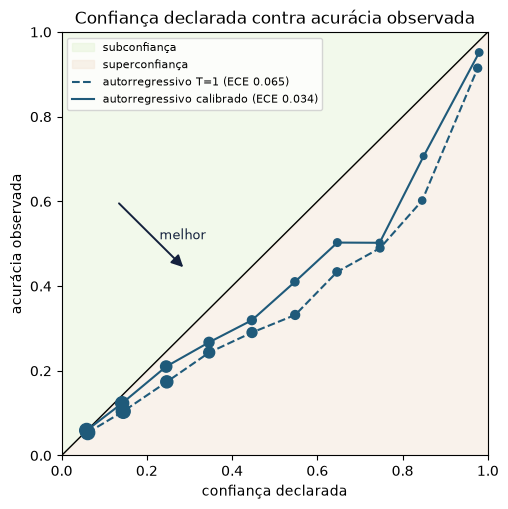

In [22]:
import torch
from slm import calibracao as cal, graficos
janelas_val, _ = janelar([d["ids"] for d in validacao], L)
janelas_val = janelas_val[torch.randperm(janelas_val.shape[0], generator=torch.Generator().manual_seed(0))]
Z, y = cal.coletar_previsoes(modelo, janelas_val, MODO, n_max=20000, dispositivo=DISPOSITIVO, sem_preenchimento=True)
T = cal.temperatura_newton(Z, y)
sistemas = {}
for rotulo, t in ((f"{MODO} T=1", 1.0), (f"{MODO} calibrado", T)):
    cf, ac = cal.confianca_acerto(Z, y, t)
    sistemas[rotulo] = dict(cal.confiabilidade(cf, ac), ece=cal.ece(cf, ac))
print(MODO, "| T =", round(T, 3), "| AUC ROC =", round(cal.auc_roc(*cal.confianca_acerto(Z, y, T)), 3))
fig = graficos.confiabilidade(sistemas)

### Técnica

**Um valor exato, que serve de régua.** No modo autorregressivo, os bits por byte são a log-verossimilhança exata. A difusão só tem um limite superior. Na comparação, o número autorregressivo é a referência fixa, e só uma difusão abaixo dele produz conclusão.

**Probabilidade não é confiança.** O diagrama de confiabilidade mostra se a confiança declarada bate com a acurácia observada. A temperatura, ajustada pelo método de Newton na validação, corrige a escala dos logits sem mudar qual token é escolhido.

## Caixa 9. Incerteza

> **O que muda em relação ao notebook da difusão.** Nada. O intervalo entre obras e a regra de comparação entre os modos são os mesmos nos dois notebooks.

### Teoria

Um número de bits por byte só vira afirmação acompanhado da sua incerteza. O protocolo do projeto usa várias sementes por modo e um bootstrap que reamostra obras e sementes. Aqui, com uma única semente, o intervalo abaixo reamostra só as obras, e por isso mede a variação entre partes do texto, não entre corridas de treino. A comparação entre os dois modos usa a diferença pareada por semente, descrita nos blocos desta caixa, e os resultados do protocolo completo estão em `docs/`, no repositório.

### Blocos de construção

**Bloco 9.1, bootstrap por obra.** Cada réplica reamostra as obras com reposição, recalcula os bits por byte como razão de somas e guarda o valor. O intervalo vai do percentil 2,5% ao 97,5% das réplicas. Reamostrar obras inteiras respeita a dependência entre capítulos da mesma obra.

**Bloco 9.2, sementes.** Uma única corrida não diz quanto o resultado varia com a inicialização e com a ordem dos dados. O protocolo do projeto treina várias sementes e reamostra em dois níveis, obras e sementes. Com $\hat\sigma$ estimado em $m$ sementes piloto, o limite superior é $\sigma_{sup} = \hat\sigma\sqrt{(m-1)/\chi^2_{0,025;\,m-1}}$, e o número de sementes é o menor $n$ com $n \ge (t_{0,975;n-1} + t_{0,8;n-1})^2 (\sigma_{sup}/\Delta_{min})^2$.

**Bloco 9.3, comparação entre os modos.** A semente $s$ fixa a inicialização e a ordem dos dados nos dois modos, e a diferença pareada é $\Delta_s = \mathrm{bpb}_{dif,s} - \mathrm{bpb}_{AR,s}$. Se o intervalo de $\Delta$ fica abaixo de zero, a difusão é melhor. Se fica acima, o modo autorregressivo supera o limite da difusão, sem conclusão sobre a verossimilhança verdadeira dela. Se contém o zero, o resultado é inconclusivo. Essa leitura precisa das corridas dos dois notebooks, e o resultado do protocolo completo fica em `docs/`, no repositório. Código em `slm/estatistica.py`.

In [23]:
from slm.estatistica import fator_sigma_sup, numero_sementes
print("fator de sigma_sup com 10 sementes:", round(fator_sigma_sup(10), 4))
for r in (0.5, 0.75, 1.0):
    print(f"sigma/Delta_min = {r}: n =", numero_sementes(r, 1.0, m=10).n)

fator de sigma_sup com 10 sementes:

 1.8256
sigma/Delta_min = 0.5: n = 9
sigma/Delta_min = 0.75: n = 17
sigma/Delta_min = 1.0: n = 29


### Aplicação

In [24]:
import numpy as np
grupos = sorted({r["grupo"] for r in res["documentos"]})
por_grupo = {g: [(r["nats"], r["bytes"]) for r in res["documentos"] if r["grupo"] == g] for g in grupos}
rng = np.random.default_rng(0)
replicas = []
for _ in range(2000):
    escolha = rng.choice(grupos, size=len(grupos), replace=True)
    nats = sum(n for g in escolha for n, _ in por_grupo[g])
    nbytes = sum(b for g in escolha for _, b in por_grupo[g])
    replicas.append(nats / nbytes / np.log(2))
print(f"{MODO} | bpb = {res['bpb']:.4f} | intervalo de 95% entre obras:", np.percentile(replicas, [2.5, 97.5]).round(4))

autoregressivo | bpb = 1.9373 | intervalo de 95% entre obras: [1.8549 2.0162]


### Técnica

**Quantas sementes?** Com 3 sementes, o intervalo de 95% do desvio padrão entre sementes vai de 0,52 a 6,28 vezes a estimativa. O projeto estima a dispersão num piloto de 10 sementes e deriva dela o número de sementes da comparação final, com um teto declarado.

**Decidir antes de olhar.** O tamanho mínimo de efeito, a grade de hiperparâmetros e o critério de leitura são congelados com hash antes das corridas que eles governam. Quando um critério precisou mudar depois dos dados, a mudança foi registrada como emenda, com a justificativa.

## Caixa 10. Leitura e memorização

> **O que muda em relação ao notebook da difusão.** O código é idêntico. Só este notebook traz a medida de memorização com muitas épocas, que foi feita neste modo.

### Teoria

Um modelo treinado por muitas épocas num corpus pequeno pode parecer coerente porque copia o texto de treino. Antes de qualquer leitura humana, cada amostra passa por dois filtros automáticos, a fração das suas palavras presentes no léxico de treino (nível N1) e o comprimento do maior trecho copiado do texto de treino.

### Blocos de construção

**Bloco 10.1, taxa de léxico.** $\rho(a) = \frac{|\{x \in \text{palavras}(a) : x \in \Lambda_{treino}\}|}{|\text{palavras}(a)|}$, com $\Lambda_{treino}$ o léxico da partição de treino.

**Bloco 10.2, maior trecho copiado.** $c(a) = \max\{k : \text{algum trecho de } k \text{ palavras de } a \text{ ocorre no texto de treino}\}$. A busca usa hash de $k$-gramas e busca binária em $k$, porque se um trecho de $k$ palavras ocorre, todos os seus subtrechos também ocorrem, e a propriedade é monótona em $k$.

**Bloco 10.3, curva de deleção.** Com a decisão $\hat y$ e $p_0 = p(\hat y \mid \text{contexto completo})$, a importância da palavra $j$ é $p_0 - p(\hat y \mid \text{contexto sem } j)$. Remover as $\mathrm{round}(f n)$ palavras mais importantes dá $C(f) = \min\big(p(\hat y \mid \text{contexto restante})/p_0, 1\big)$, e $\mathrm{AUC} = \int_0^1 C(f)\, df$ pela regra do trapézio. $C(1)$ mede o viés intrínseco.

**Bloco 10.4, Spearman.** $\rho_S$ é a correlação de Pearson entre os postos de $p_0$ e os postos da AUC, item a item. Código em `slm/leitura.py` e `slm/delecao.py`.

In [25]:
import numpy as np
from scipy.stats import rankdata, spearmanr
x10, y10 = np.array([0.2, 0.5, 0.1, 0.9]), np.array([0.7, 0.4, 0.8, 0.3])
print("Spearman à mão:", round(float(np.corrcoef(rankdata(x10), rankdata(y10))[0, 1]), 4),
      "| scipy:", round(float(spearmanr(x10, y10).statistic), 4))
grade = np.linspace(0, 1, 11)
C10 = np.array([1, .6, .5, .45, .4, .38, .36, .35, .34, .33, .33])
print("AUC pela regra do trapézio:", round(float(np.trapezoid(C10, grade)), 4))

Spearman à mão: -1.0 | scipy: -1.0
AUC pela regra do trapézio: 0.4375


### Aplicação

In [26]:
from slm.leitura import IndiceTreino, lexico, taxa_lexico
textos_treino = [d["texto"] for d in ler_documentos(CORPUS, "treino")]
lex = lexico(textos_treino)
indice = IndiceTreino(textos_treino)
for a in amostras.tolist():
    t = como_texto(a)
    print("taxa de léxico:", round(taxa_lexico(t, lex), 3), "| maior trecho copiado:", indice.maior_trecho(t), "palavras")

taxa de léxico: 0.893 | maior trecho copiado: 5 palavras


taxa de léxico: 0.857 | maior trecho copiado: 4 palavras
taxa de léxico: 0.882 | maior trecho copiado: 4 palavras


### Curva de deleção

Quanto uma previsão depende do contexto? Para cada trecho de 50 palavras, palavras do contexto são removidas, começando pelas que mais sustentam a decisão, e a probabilidade do token decidido é acompanhada em relação à original. Com 100% removido o contexto fica vazio, e o que resta é o viés intrínseco do modelo. A curva com ordem aleatória serve de referência.

AUC por importância 0.102 | aleatória 0.463 | contexto vazio 0.067 | Spearman p0 x AUC -0.37


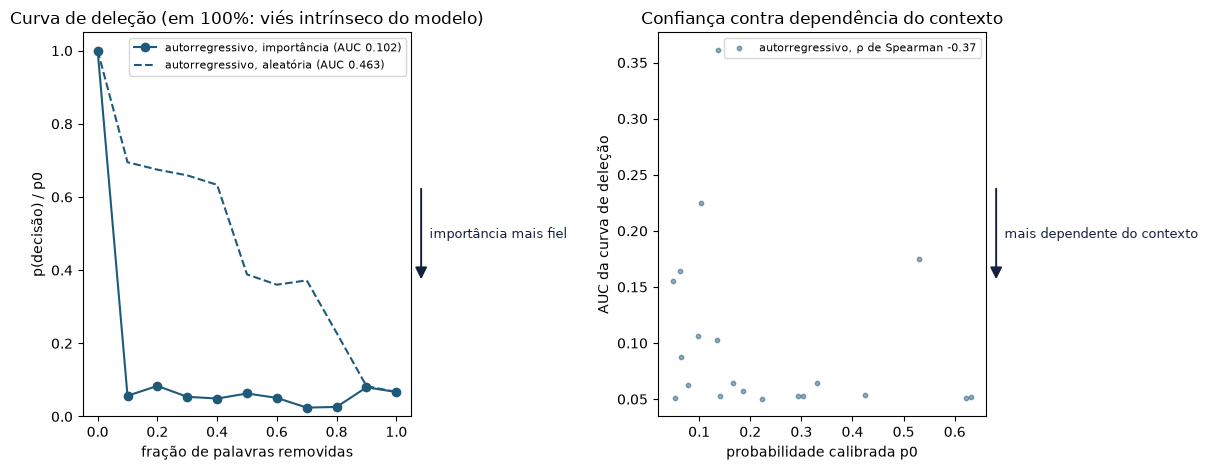

In [27]:
from slm import delecao
itens = delecao.itens([d["texto"] for d in ler_documentos(CORPUS, "teste")], tok, n_itens=20, n_palavras=50)
res_del = delecao.analisar(modelo, MODO, tok, itens, L, T=T, dispositivo=DISPOSITIVO)
print(f"AUC por importância {res_del['auc_importancia_media']:.3f} | aleatória {res_del['auc_aleatoria_media']:.3f} | "
      f"contexto vazio {res_del['p_vazio_relativo_medio']:.3f} | Spearman p0 x AUC {res_del['spearman_p0_auc']['rho']:.2f}")
fig = graficos.delecao({MODO: res_del})

### Técnica

**Coerente ou copiado?** Um modelo treinado por muitas épocas pode parecer coerente porque reproduz trechos do texto de treino. O filtro de cópia mede o maior trecho copiado e descarta a amostra que passa do que se observa entre textos humanos. A taxa de descarte é relatada como medida de memorização.

**Sobreajuste também é recitação.** Sem dropout e com taxa $10^{-3}$, o modelo autorregressivo treinado por 256 épocas chegou a 5,6 bits por byte na validação, muito pior que com 16 épocas. Em 16 amostras de 256 tokens por corrida, o maior trecho copiado do texto de treino teve mediana de 4 palavras com 16 épocas e de 144 a 150 palavras com 256 épocas, com máximo de 180. Com dropout de 0,2 e taxa $3 \times 10^{-4}$, as mesmas 256 épocas deram mediana de 5 a 5,5 palavras, ainda com amostras isoladas de 44 e 95 palavras copiadas. O sobreajuste apareceu nas duas formas, como previsões erradas e confiantes no texto novo e como recitação do texto de treino. A medida está em `scripts/medir_copia.py`, e o resultado de cada corrida em `runs/<corrida>/copia.json`.

**O viés que sobra sem contexto.** Na curva de deleção, com 100% do contexto removido, a rede ainda dá probabilidade à decisão original. Esse resto mede o viés intrínseco do modelo, o que ele sabe sem olhar a entrada.

## Exercícios

1. Na caixa 0, defina `CORPUS = "B"` e rode tudo de novo. O que muda no código e o que continua igual?
2. Na caixa 7, passe a `gerar_ar` um `prefixo` com os ids de uma frase sua. Até onde a continuação mantém o assunto?
3. Na caixa 0, dobre `EPOCAS_AULA`. Os bits por byte de validação caem na mesma proporção que a perda de treino? O que a diferença indica?
4. Na caixa 4, o que aconteceria com a perda de treino se a entrada não fosse deslocada pelo `[BOS]`, e por que esse número não diria nada sobre a qualidade do modelo?
5. Na curva de deleção, o que significa a curva ficar perto de 1 mesmo com 100% do contexto removido?
6. Rode o notebook `slm_difusao.ipynb` com a mesma configuração e compare os bits por byte. Que conclusão a leitura assimétrica da caixa 9 permite tirar?

## Referências

A lista completa de referências, todas de acesso aberto, está em `referencias/REFERENCIAS.md`, no repositório.